# 06 · Real benzene/water LLE and stability with SAFT-γ Mie

The main course uses actual ThermoWeave models and real chemical components. See the [course index](../tutorials.md).

<a class="md-button" href="06_liquid_stability_and_flash.ipynb" download>Download notebook</a>


At 290 K and 1 atm, calculate the two-liquid split of real benzene + water.
This temperature is above benzene's melting point, so the demonstration is
liquid-only. Inspect stable phase compositions, phase amounts, activities and
Gibbs energy using the actual SAFT model. Notebook 10 adds the measured solid
free energy and finds the binary SLLE invariant.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import SAFTgammaMie
from thermoweave.equilibrium.reduced_held import ReducedChart,ReducedHELD
from _support import COMPONENTS,held_settings,check_flash,phase_table
names=['benzene','water'];T=290.
model=SAFTgammaMie.from_smiles({n:COMPONENTS[n]['smiles'] for n in names},pressure_Pa=101325.)
chart=ReducedChart.build([0,0],[COMPONENTS[n]['molar_mass_g_mol'] for n in names])
feed=np.array([.5,.5])
result=ReducedHELD(model,T,chart,held_settings()).flash(feed)
print(phase_table(result,names))
print(check_flash(model,T,feed,result))
assert result.phase_kinds==['liquid','liquid']
assert result.gibbs<result.gibbs_feed

SAFT-gamma-Mie automatic assignment: benzene
  SMILES: c1ccccc1
  Formula: C6H6
  Groups: {'aCH': 6}
  Atom-labelled SMILES (labels are 1-based): [cH:1]1[cH:2][cH:3][cH:4][cH:5][cH:6]1
  Method: specific SMARTS groups first; complete, non-overlapping atom coverage.
  aCH x6:
    atoms 1:C(H1)
    atoms 2:C(H1)
    atoms 3:C(H1)
    atoms 4:C(H1)
    atoms 5:C(H1)
    atoms 6:C(H1)
    rule: aromatic CH in a six-membered ring; SMARTS [c;H1;r6]
    parameters: 10.1021/acs.jced.0c00746
  Coverage: 6/6 heavy atoms; each atom assigned once; elemental composition including H checked.
  Unlike interaction coverage is checked separately with missing_interactions().


SAFT-gamma-Mie automatic assignment: water
  SMILES: O
  Formula: H2O
  Groups: {'H2O': 1}
  Atom-labelled SMILES (labels are 1-based): [OH2:1]
  Method: specific SMARTS groups first; complete, non-overlapping atom coverage.
  H2O x1:
    atoms 1:O(H2)
    rule: whole water molecule; SMARTS [O;H2;X2]
    parameters: 10.1021/acs.jced.0c00746
  Coverage: 1/1 heavy atoms; each atom assigned once; elemental composition including H checked.
  Unlike interaction coverage is checked separately with missing_interactions().


[{'phase': 'liquid', 'mole_fraction_of_total': 0.501004551814858, 'mass_fraction_of_total': 0.812783480864861, 'x_benzene': 0.997704445323256, 'x_water': 0.002295554676744174}, {'phase': 'liquid', 'mole_fraction_of_total': 0.49899544818514197, 'mass_fraction_of_total': 0.187216519135139, 'x_benzene': 0.0002916490073757, 'x_water': 0.9997083509926243}]
{'species_balance_error_mol': 3.175237850427948e-14, 'liquid_mu_error_over_RT': 9.800246551783243e-13, 'solid_saturation_error_over_RT': 0.0, 'gibbs_reconstruction_error_over_RT': np.float64(2.8196195378527023e-14), 'phase_mole_fractions': [0.5010045518148437, 0.49899544818512775], 'phase_mass_fractions': [0.812783480864861, 0.187216519135139]}


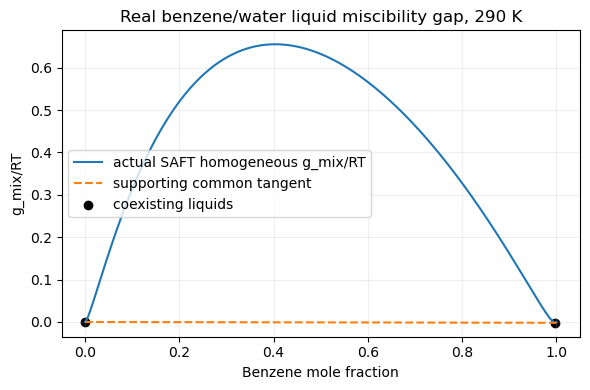

In [2]:
X=np.asarray(sorted(result.mole_fractions,key=lambda x:x[0]))
mu=np.log(X)+model.ln_activity_coefficients_batch(T,X)
np.testing.assert_allclose(mu[0],mu[1],atol=5e-7)
xs=np.unique(np.r_[np.linspace(0,1,250),X[:,0]])
compositions=np.column_stack([xs,1-xs])
lng=model.ln_activity_coefficients_batch(T,compositions)
g=np.sum(compositions*(np.log(np.maximum(compositions,1e-300))+lng),axis=1)
plane=compositions@mu[0]
assert np.min(g-plane)>-2e-7
fig,ax=plt.subplots(figsize=(6,4))
ax.plot(xs,g,label='actual SAFT homogeneous g_mix/RT')
ax.plot(xs,plane,'--',label='supporting common tangent')
ax.scatter(X[:,0],X@mu[0],color='black',label='coexisting liquids')
ax.set(xlabel='Benzene mole fraction',ylabel='g_mix/RT',title='Real benzene/water liquid miscibility gap, 290 K')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();plt.show()

The supporting-plane survey and independent balances complement the
solver's numerical certification; they are not unconditional global proofs.
Change the feed inside the gap and verify fixed liquid compositions with
changing phase amounts. Continue to the binary and ternary SLLE notebooks.